# Jeux globaux — la coordination avec information incomplète

**Morris (1994) · Kay & Perry (2006) · Hagen & Köbis (2016)**

Un jeu de coordination à **information complète** porte plusieurs équilibres de Nash : les deux accords (l'un efficace, l'autre non) **et** un équilibre mixte instable. La question n'est pas de trouver *un* équilibre, mais de savoir **lequel sera joué**.

Le dispositif des **jeux globaux** répond : chaque joueur observe un **signal bruité** d'un fondamental commun `θ`. Le bruit, loin d'être un défaut, **expulse la multiplicité** — les équilibres de coordination aveugle sont repoussés vers les queues du prior, hors du support effectif des signaux, où il ne reste qu'un équilibre **interne et symétrique** — qui **sélectionne de façon robuste** l'accord efficace quand le signal devient précis.

Ce carnet **mesure** ce résultat : les équilibres de seuil à chaque `σ` (tous, pas seulement le sélectionné), leur probabilité interne, et l'efficacité ex-post quand le bruit `σ` diminue.

**Prérequis** : [02 Forme normale](GameTheory-02-NormalForm-Python.ipynb) · [04 Nash](GameTheory-04-NashEquilibrium-Python.ipynb) · [11 Jeux bayésiens](GameTheory-11-BayesianGames-Python.ipynb).

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt

# Fonction de répartition de la normale centrée réduite (auto-contenu, sans scipy)
def Phi(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

rng = np.random.default_rng(2026)
print("imports OK — Phi(0) =", Phi(0.0), "  Phi(1) =", round(Phi(1.0), 4))

imports OK — Phi(0) = 0.5   Phi(1) = 0.8413


## 1. Le jeu de coordination complet — la multiplicité d'origine

Deux joueurs choisissent en même temps **H** (haut) ou **L** (bas). Un fondamental `θ` décide quelle action est **efficace** : `θ > 0` → H, `θ ≤ 0` → L. La fonction de gains s'écrit sur les deux états — c'est **la même** pour tout le carnet :

**État `θ > 0`** (H est le projet efficace) :

|  | **H** | **L** |
|---|---|---|
| **H** | 2, 2 | 0, 0 |
| **L** | 0, 0 | 1, 1 |

**État `θ ≤ 0`** (L est le projet efficace) :

|  | **H** | **L** |
|---|---|---|
| **H** | 1, 1 | 0, 0 |
| **L** | 0, 0 | 2, 2 |

Se coordonner rapporte toujours — mais sur le **bon** projet, le double. Dans un état connu :

- **Deux équilibres de Nash purs** : la coordination efficace (gain 2 chacun) et la coordination inefficace (gain 1 chacun).
- **Un équilibre mixte** : chacun joue H avec une probabilité qui indifférise l'autre.

Trois équilibres par état, un seul efficace : **c'est la multiplicité** que le jeu global va trancher.

In [2]:
# θ > 0 : H est l'action efficace
A = np.array([[2, 0],
              [0, 1]])          # gains du joueur Ligne (H = ligne 0, L = ligne 1)
a11, a12, a21, a22 = A[0, 0], A[0, 1], A[1, 0], A[1, 1]

# Équilibre mixte symétrique : chacun joue H avec p tel que l'autre soit indifférent
#   2p + 0(1-p)  =  0p + 1(1-p)   =>   2p = 1 - p   =>   p = 1/3
p_mixte = (a22 - a21) / ((a11 - a12) + (a22 - a21))
print("Équilibres de Nash à information complète (θ > 0) :")
print(f"  pur 1  : (H, H)  — efficace,    gain 2")
print(f"  pur 2  : (L, L)  — inefficace,  gain 1")
print(f"  mixte  : chacun joue H avec p = {p_mixte:.4f}  (instable)")

Équilibres de Nash à information complète (θ > 0) :
  pur 1  : (H, H)  — efficace,    gain 2
  pur 2  : (L, L)  — inefficace,  gain 1
  mixte  : chacun joue H avec p = 0.3333  (instable)


## 2. Le dispositif du jeu global — un signal bruité

`θ` est inconnu. Chaque joueur `i` reçoit un **signal** :

    s_i = θ + ε_i ,   ε_i ~ N(0, σ²)

`θ ~ N(0, 1)` (a priori). Les deux signaux sont **corrélés** — ils partagent `θ` : c'est cette corrélation qui rend le jeu global *global*.

**Stratégie à seuil** : un joueur joue H s'il reçoit `s_i ≥ k` (son seuil). Un équilibre à seuil est un `k*` où un joueur qui observe exactement `s_i = k*` est indifférent entre H et L — **et** qui passe le **test de meilleure réponse** : face au seuil adverse `k*` fixé, préférer strictement L juste sous `k*`, strictement H juste au-dessus.

**Ce que le bruit fait vraiment à la multiplicité** : l'équation d'indifférence peut croiser **plusieurs fois** (mesuré : trois croisements à `σ = 0.5`) et — contre-intuitivement — les croisements latéraux **passent eux aussi** le test de meilleure réponse. La multiplicité du jeu complet ne disparaît donc pas à bruit fini : le bruit **l'expulse vers les queues du prior**. Mesuré en section 3 : les deux équilibres de coordination aveugle survivent à `|k*| = 12.206` quand `σ = 0.05` — une région où le signal d'aucun joueur n'atterrit en pratique — se rapprochent quand `σ` grandit (`±1.428` à `σ = 0.5`), puis s'annihilent entre `σ = 0.7` et `σ = 0.8`. L'unicité est un énoncé **asymptotique** : c'est à `σ → 0` que les équilibres parasites partent à l'infini.

In [3]:
# À posteriori : sachant s,  θ | s ~ N(mu(s), v)
#   précision θ = 1/1,  précision ε = 1/σ²  =>  v = 1 / (1 + 1/σ²) = σ² / (1 + σ²)
#   mu(s) = v · (s / σ²) = s / (1 + σ²)
def posterior(s, sigma):
    v  = sigma**2 / (1.0 + sigma**2)
    mu = s / (1.0 + sigma**2)
    return mu, v

def p_theta_pos(s, sigma):
    """P(θ > 0 | s)"""
    mu, v = posterior(s, sigma)
    return Phi(mu / math.sqrt(v))

# Probabilité que l'ADVERSAIRE joue H, sachant mon signal s (stratégie à seuil k, symétrique)
#   s_2 | s_1 = s ~ N( mu(s), v + σ² )   (même θ, bruit indépendant)
def p_other_H(s, k, sigma):
    mu, v = posterior(s, sigma)
    var_other = v + sigma**2
    return Phi((mu - k) / math.sqrt(var_other))

print("posterior(s=1, σ=0.5)  ->  μ, v =", [round(x, 4) for x in posterior(1.0, 0.5)])
print("P(θ>0 | s=1, σ=0.5)     =", round(p_theta_pos(1.0, 0.5), 4))
print("P(autre H | s=1, k=0, σ=0.5) =", round(p_other_H(1.0, 0.0, 0.5), 4))

posterior(s=1, σ=0.5)  ->  μ, v = [0.8, 0.2]
P(θ>0 | s=1, σ=0.5)     = 0.9632
P(autre H | s=1, k=0, σ=0.5) = 0.8835


## 3. Les équilibres de seuil — l'équation d'indifférence

Une **seule** fonction de gains pour tout le carnet — celle de la section 1, étendue à `θ ≤ 0` par symétrie (c'est maintenant L qui est efficace) :

|  | θ > 0 | θ ≤ 0 |
|---|---|---|
| `(H, H)` | **2** | 1 |
| `(L, L)` | 1 | **2** |
| désaccord | 0 | 0 |

À `θ > 0` connue, on retrouve **exactement** la matrice `[[2, 0], [0, 1]]` de la section 1 — et ses trois équilibres. Le jeu global remplace la connaissance de `θ` par le signal `s`.

Sachant mon signal `s`, mes gains espérés :

    Gain(H | s) = 2·P(θ > 0 ∧ s₂ ≥ k | s) + 1·P(θ ≤ 0 ∧ s₂ ≥ k | s)
    Gain(L | s) = 1·P(θ > 0 ∧ s₂ <  k | s) + 2·P(θ ≤ 0 ∧ s₂ <  k | s)

Le point subtil : `θ` et le signal adverse `s₂` descendent du **même** `θ` — les événements `θ > 0` et `s₂ ≥ k` sont conditionnellement **dépendants**. Ces probabilités **conjointes** s'évaluent en intégrant sur la postérieure de `θ`, jamais comme produit de marginales : à `s = k = 0`, `σ = 0.5`, la conjointe vaut `0.366` (corrélation conditionnelle `2/3`) là où le produit des marginales vaut `0.25`.

Un seuil `k*` est un équilibre s'il résout `Gain(H | k*) = Gain(L | k*)` **et** passe le test de meilleure réponse : face au seuil adverse `k*` fixé, un joueur préfère strictement L juste sous `k*` et strictement H juste au-dessus. La symétrie exacte du modèle (`θ → −θ`, `H ↔ L`) garantit que `k* = 0` est de ceux-ci à chaque `σ` — la cellule suivante mesure ce qui existe **en plus** de lui.

In [4]:
# Probabilites conjointes : P(theta>0 et s2>=k | s) par integration sur la posterior de theta.
# theta et s2 partagent le meme theta -> jamais un produit de marginales.
N_INT = 20000   # points d'integration. A 4000, le bruit numerique (~1e-3) atteint l'ordre
                # de f pres d'un croisement : des racines fantomes apparaissent, d'autres manquent.

phi_std = lambda x: np.exp(-0.5*x*x)/np.sqrt(2.0*np.pi)

def _erf_vec(x):
    # Abramowitz-Stegun 7.1.26 (numpy 2.x n'expose plus np.erf)
    sign = np.sign(x); ax = np.abs(x); t = 1.0/(1.0+0.3275911*ax)
    y = 1.0 - (((((1.061405429*t-1.453152027)*t)+1.421413741)*t-0.284496736)*t+0.254829592)*t*np.exp(-ax*ax)
    return sign*y

def _trapz(y, x):
    # trapezes manuels (np.trapz est deprecie)
    return float(np.sum(0.5*(y[1:]+y[:-1])*(x[1:]-x[:-1])))

def joint_HH(s, k, sigma, n=N_INT):
    """P(theta > 0 ET s2 >= k | s) : posterior de theta, puis P(s2>=k | theta)."""
    mu, v = posterior(s, sigma); sd = np.sqrt(v)
    xs = np.linspace(0.0, mu+12*sd, n)
    dens = phi_std((xs-mu)/sd)/sd
    return _trapz(dens*(0.5*(1.0+_erf_vec((xs-k)/(sigma*np.sqrt(2.0))))), xs)

def joint_LL(s, k, sigma, n=N_INT):
    """P(theta < 0 ET s2 < k | s)."""
    mu, v = posterior(s, sigma); sd = np.sqrt(v)
    xs = np.linspace(mu-12*sd, 0.0, n)
    dens = phi_std((xs-mu)/sd)/sd
    return _trapz(dens*(0.5*(1.0+_erf_vec((k-xs)/(sigma*np.sqrt(2.0))))), xs)

def indifference(s, k, sigma):
    # Gain(H|s) - Gain(L|s) avec la fonction de gains unique de la section 3 :
    # Gain(H|s) = P(s2>=k|s) + P(theta>0 et s2>=k|s), Gain(L|s) = P(s2<k|s) + P(theta<0 et s2<k|s)
    return (2.0*p_other_H(s, k, sigma) - 1.0) + (joint_HH(s, k, sigma) - joint_LL(s, k, sigma))

def best_response_ok(sigma, k, delta=1e-3):
    """Test de meilleure reponse (necessaire) : face au seuil adverse k FIXE,
    un joueur prefere L juste sous k et H juste au-dessus."""
    return indifference(k-delta, k, sigma) < 0 < indifference(k+delta, k, sigma)

def side_equilibria(sigma, s_min=0.05, s_max=16.0, n_grid=481):
    """Seuils lateraux (> s_min) de f(s) = indifference(s, s, sigma). f est IMPAIRE
    (symetrie theta -> -theta, H <-> L) : 0 est toujours racine et les autres
    viennent par paires +/- ; on scanne donc s > 0 seulement."""
    ss = np.linspace(s_min, s_max, n_grid)
    ff = np.array([indifference(s, s, sigma) for s in ss])
    roots = []
    for i in range(len(ss)-1):
        if ff[i]*ff[i+1] < 0:
            a, b, fa = ss[i], ss[i+1], ff[i]
            for _ in range(60):
                m = 0.5*(a+b); fm = indifference(m, m, sigma)
                if abs(fm) < 1e-10 or (b-a) < 1e-10: break
                if (fm < 0) == (fa < 0): a, fa = m, fm
                else: b = m
            roots.append(0.5*(a+b))
    return roots

def solve_cutoff(sigma):
    """Equilibres de seuil a sigma -> (k* selectionne, liste complete). La symetrie
    exacte donne k* = 0 a chaque sigma -- verifie par meilleure reponse, pas suppose.
    Les lateraux, quand ils existent, sont les reliques de la coordination aveugle."""
    sides = side_equilibria(sigma)
    equilibria = sorted(-k for k in sides) + [0.0] + sorted(sides)
    kstar = 0.0 if best_response_ok(sigma, 0.0) else float("nan")
    return kstar, equilibria

def play_H_prob(sigma, k):
    """P(s_i >= k) pour theta~N(0,1) : proportion de joueurs qui jouent H."""
    return 1.0 - Phi(k / math.sqrt(1.0 + sigma**2))

# Le fait qui motive les conjointes (independant des gains) :
print(f"Conjointe vs produit de marginales a s=k=0, sigma=0.5 : "
      f"P(theta>0 et s2>=0 | s=0) = {joint_HH(0,0,0.5):.4f}  contre  "
      f"P(theta>0)*P(s2>=0) = {p_theta_pos(0,0.5)*p_other_H(0,0,0.5):.4f}")
print()
print("Equilibres de seuil par bruit (* = test de meilleure reponse passe, x = echoue) :")
print("sigma   seuils d'equilibre                          P(jouer H) par seuil")
for sigma in [2.0, 1.0, 0.8, 0.7, 0.5, 0.2, 0.1, 0.05]:
    _, eqs = solve_cutoff(sigma)
    ks = "  ".join(f"{k:+.3f}{'*' if best_response_ok(sigma, k) else 'x'}" for k in eqs)
    ph = "  ".join(f"{play_H_prob(sigma, k):.3f}" for k in eqs)
    print(f"{sigma:<6}  {ks}    |  {ph}")
print()
print("Pourquoi k*=0 exactement : les gains sont symetriques sous (theta -> -theta, H <-> L),")
print("donc indifference(s,s,sigma) est impaire en s -- 0 est toujours racine, et P(jouer H)=1/2.")
print()
sigma = 0.5
_, eqs = solve_cutoff(sigma)
print(f"A sigma={sigma}, les TROIS seuils passent le test de meilleure reponse (seuil adverse fixe) :")
for k in eqs:
    print(f"  k={k:+.3f} : Gain(H)-Gain(L) a s=k-0.001 : {indifference(k-1e-3, k, sigma):+.4f}, "
          f"a s=k+0.001 : {indifference(k+1e-3, k, sigma):+.4f}")

# Controle Monte-Carlo de la formule complete, en un point NON trivial (s=0.3, k=0, sigma=0.5)
s0, k0 = 0.3, 0.0
rng = np.random.default_rng(7)
mu, v = posterior(s0, sigma)
T  = rng.normal(mu, np.sqrt(v), 400_000)
S2 = T + rng.normal(0.0, sigma, 400_000)
# gains simules etat par etat : (H,H)=2 si theta>0 sinon 1 ; (L,L)=1 si theta>0 sinon 2
payoff_H = np.where(T > 0, 2.0, 1.0) * (S2 >= k0)
payoff_L = np.where(T > 0, 1.0, 2.0) * (S2 <  k0)
print()
print(f"Controle MC a s={s0}, k={k0}, sigma={sigma} (gains simules etat par etat) :")
print(f"  analytique {indifference(s0, k0, sigma):+.4f}   simulation {np.mean(payoff_H - payoff_L):+.4f}")

Conjointe vs produit de marginales a s=k=0, sigma=0.5 : P(theta>0 et s2>=0 | s=0) = 0.3661  contre  P(theta>0)*P(s2>=0) = 0.2500

Equilibres de seuil par bruit (* = test de meilleure reponse passe, x = echoue) :
sigma   seuils d'equilibre                          P(jouer H) par seuil


2.0     +0.000*    |  0.500


1.0     +0.000*    |  0.500


0.8     +0.000*    |  0.500


0.7     -0.597*  +0.000*  +0.597*    |  0.688  0.500  0.312


0.5     -1.428*  +0.000*  +1.428*    |  0.899  0.500  0.101


0.2     -3.137*  +0.000*  +3.137*    |  0.999  0.500  0.001


0.1     -6.137*  +0.000*  +6.137*    |  1.000  0.500  0.000


0.05    -12.206*  +0.000*  +12.206*    |  1.000  0.500  0.000

Pourquoi k*=0 exactement : les gains sont symetriques sous (theta -> -theta, H <-> L),
donc indifference(s,s,sigma) est impaire en s -- 0 est toujours racine, et P(jouer H)=1/2.



A sigma=0.5, les TROIS seuils passent le test de meilleure reponse (seuil adverse fixe) :
  k=-1.428 : Gain(H)-Gain(L) a s=k-0.001 : -0.0013, a s=k+0.001 : +0.0013
  k=+0.000 : Gain(H)-Gain(L) a s=k-0.001 : -0.0021, a s=k+0.001 : +0.0021
  k=+1.428 : Gain(H)-Gain(L) a s=k-0.001 : -0.0013, a s=k+0.001 : +0.0013

Controle MC a s=0.3, k=0.0, sigma=0.5 (gains simules etat par etat) :
  analytique +0.6235   simulation +0.6252


## 4. La sélection robuste — quand le bruit se resserre

La propriété forte : quand `σ → 0` (signal précis), l'équilibre sélectionné `k* = 0` **coïncide avec l'action efficace** — les joueurs jouent H exactement quand `θ > 0`. Le bruit fin n'empêche pas la sélection ; c'est lui qui la garantit, en repoussant les équilibres de coordination aveugle hors du support effectif des signaux.

Mesurons l'**efficacité ex-post** : en simulant l'équilibre sélectionné (chaque joueur joue H si `s_i ≥ k*`), quelle fraction du temps les deux joueurs jouent-ils l'action **efficace** (coordonnés sur le bon projet) ?

In [5]:
def efficiency(sigma, n=40000, seed=2026):
    """Fraction des mondes où les deux joueurs se coordonnent sur l'action efficace
    (H si theta > 0, L sinon) à l'équilibre sélectionné k*."""
    k, _ = solve_cutoff(sigma)
    r = np.random.default_rng(seed)
    theta = r.normal(0.0, 1.0, n)
    s1 = theta + r.normal(0.0, sigma, n)
    s2 = theta + r.normal(0.0, sigma, n)
    a1 = s1 >= k
    a2 = s2 >= k
    coordinated = (a1 == a2) & (a1 == (theta > 0))
    return coordinated.mean()

print("Efficacité ex-post de l'équilibre sélectionné (coordonnés sur le bon projet) :")
for sigma in [2.0, 1.0, 0.5, 0.2, 0.1, 0.05]:
    print(f"  σ = {sigma:<4}  ->  {efficiency(sigma):.3f}")

Efficacité ex-post de l'équilibre sélectionné (coordonnés sur le bon projet) :


  σ = 2.0   ->  0.428


  σ = 1.0   ->  0.584


  σ = 0.5   ->  0.751


  σ = 0.2   ->  0.893


  σ = 0.1   ->  0.947


  σ = 0.05  ->  0.973


## 5. Lecture — le bruit expulse la multiplicité, la précision sélectionne

- **`k* = 0` exactement, à chaque `σ`** : les gains sont symétriques sous l'échange `(θ → −θ, H ↔ L)`, donc `indifference(s, s, σ)` est impaire en `s` — le seuil sélectionné est le signal médian, et `P(jouer H) = 1/2`. L'asymétrie `(H,H) = 2 / (L,L) = 1` est **conditionnelle à l'état** : elle récompense la coordination efficace, elle ne biaise pas le seuil.
- **La multiplicité est expulsée, pas détruite** : à `σ = 0.5`, l'équation croise trois fois et **les trois seuils passent le test de meilleure réponse** — les deux latéraux (`±1.428`) sont les reliques bruitées des équilibres de coordination aveugle du jeu complet : jouer H presque toujours (`P(jouer H) = 0.899`) ou L presque toujours (`0.101`). À `σ = 0.05` ils survivent à `±12.206` — où le prior n'a pratiquement plus de masse, hors du support effectif des signaux. Entre `σ = 0.7` et `σ = 0.8` ils s'annihilent. L'unicité du jeu global est **asymptotique** : `σ → 0` envoie les équilibres parasites à l'infini.
- **`σ → 0`** : l'efficacité tend vers **1** (0,973 à `σ = 0.05`) — l'accord efficace `(H,H)` si `θ > 0` / `(L,L)` sinon est sélectionné avec quasi-certitude.
- **`σ` grand** : l'efficacité descend (0,751 à `σ = 0.5` ; 0,584 à `σ = 1.0` ; 0,428 à `σ = 2.0`) — le signal est trop bruité pour suivre `θ`, et la coordination elle-même se dégrade.

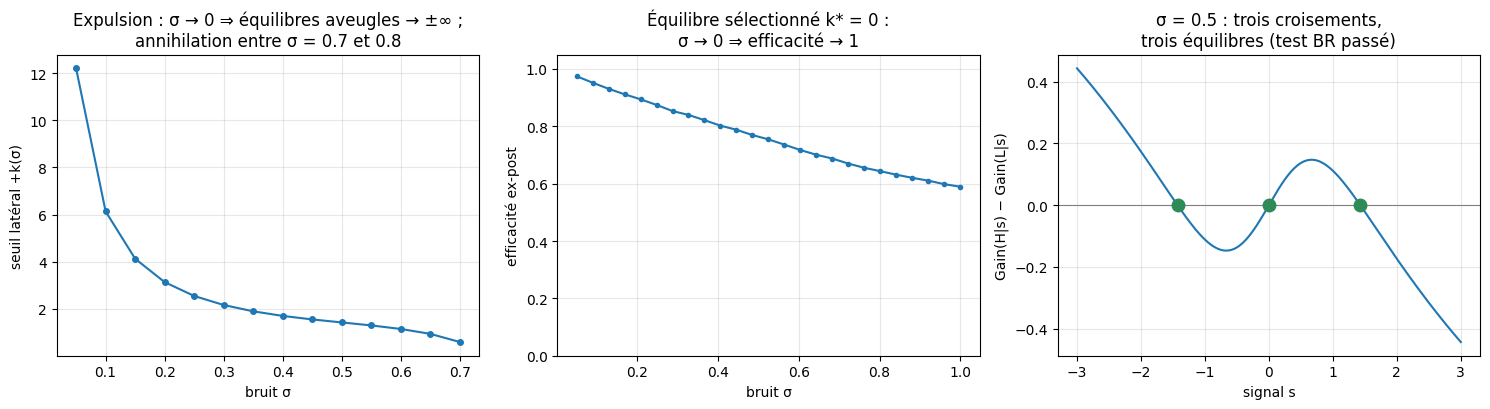

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

# Panneau 1 : l'expulsion -- les equilibres lateraux partent vers les queues quand sigma -> 0
sig_scan = np.linspace(0.05, 0.8, 16)
lat = np.array([side_equilibria(s_, n_grid=301)[0] if side_equilibria(s_, n_grid=301) else np.nan
                for s_ in sig_scan])
ax[0].plot(sig_scan, lat, marker='o', ms=4)
ax[0].set_xlabel('bruit σ'); ax[0].set_ylabel('seuil latéral +k(σ)')
ax[0].set_title("Expulsion : σ → 0 ⇒ équilibres aveugles → ±∞ ;\nannihilation entre σ = 0.7 et 0.8")
ax[0].grid(alpha=0.3)

# Panneau 2 : efficacite ex-post de l'equilibre selectionne k*=0
sigmas = np.linspace(0.05, 1.0, 25)
effs = [efficiency(s, n=4000) for s in sigmas]
ax[1].plot(sigmas, effs, marker='o', ms=3)
ax[1].set_ylim(0, 1.05); ax[1].set_xlabel('bruit σ'); ax[1].set_ylabel('efficacité ex-post')
ax[1].set_title('Équilibre sélectionné k* = 0 :\nσ → 0 ⇒ efficacité → 1')
ax[1].grid(alpha=0.3)

# Panneau 3 : l'equation d'indifference a sigma=0.5 -- trois croisements, trois equilibres
ss = np.linspace(-3, 3, 241)
fs = np.array([indifference(s, s, 0.5) for s in ss])
ax[2].plot(ss, fs, lw=1.5)
ax[2].axhline(0, color='gray', lw=0.8)
_, eqs05 = solve_cutoff(0.5)
for r in eqs05:
    ax[2].plot([r], [0], marker='o', ms=9, color='seagreen')
ax[2].set_xlabel('signal s'); ax[2].set_ylabel('Gain(H|s) − Gain(L|s)')
ax[2].set_title('σ = 0.5 : trois croisements,\ntrois équilibres (test BR passé)')
ax[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

***
### Exercice 1 — la multiplicité du jeu complet

Calculez la probabilité de l'action H (ligne 0) à l'équilibre mixte d'un jeu de coordination générique `[[a, b], [c, d]]`.

In [7]:
def mixed_eq_prob(a, b, c, d):
    """Probabilité de l'action H (ligne 0) à l'équilibre mixte du jeu [[a, b], [c, d]].

    Indice : l'équilibre mixte indifférise l'adversaire — sa probabilité de ligne 0
    annule l'écart de gain entre les colonnes.
    """
    # TODO etudiant
    return None
# (le cas du carnet : a=2, b=0, c=0, d=1  ->  1/3)

### Exercice 2 — l'indifférence au seuil

Complétez la fonction qui, pour un `σ` donné, calcule l'indifférence d'un joueur observant `s` face au seuil `k` (section 3).

In [8]:
def cutoff_indifference(s, k, sigma):
    """Gain(H|s) - Gain(L|s) avec la fonction de gains unique — s'annule à s = k = k*."""
    # TODO etudiant : ce n'est PAS un produit de marginales — θ et le signal s_2 de
    # l'adversaire sont corrélés par θ. Avec (H,H)=2 si θ>0 sinon 1 et (L,L)=1 si
    # θ>0 sinon 2 (désaccord 0), décomposer :
    #   Gain(H|s) = P(s_2 ≥ k | s) + P(θ>0 ∧ s_2 ≥ k | s)
    #   Gain(L|s) = P(s_2 <  k | s) + P(θ<0 ∧ s_2 <  k | s)
    # et intégrer les probabilités CONJOINTES sur la postérieure de θ (section 3).
    # Indice : la symétrie du modèle dit déjà que k* = 0 -- votre code doit le retrouver.
    return None

### Exercice 3 — lire la sélection

En faisant varier `σ`, à partir de quelle valeur l'efficacité ex-post dépasse-t-elle **95 %** ? Qu'est-ce que cela dit sur le lien entre **précision de l'information** et **sélection de l'équilibre** ?

In [9]:
# TODO etudiant : faire varier σ et trouver le seuil d'efficacité 95 %
result = None  # TODO etudiant
print("Exercice 3 à compléter")

Exercice 3 à compléter


## En résumé

- Le jeu de coordination complet porte **trois** équilibres par état (deux purs, un mixte) : la multiplicité.
- Le **jeu global** (signal bruité d'un fondamental commun) garde `k* = 0` à chaque `σ` — équilibre **exact par symétrie**, à probabilité interne `1/2` — et **expulse** les deux équilibres de coordination aveugle vers les queues du prior : mesurés à `±12.206` pour `σ = 0.05`, disparus entre `σ = 0.7` et `σ = 0.8`. La multiplicité n'est pas détruite à bruit fini : elle est **repoussée hors du support effectif des signaux** — l'unicité se gagne à la limite `σ → 0`.
- Quand le signal devient **précis** (`σ → 0`), l'équilibre sélectionné **coïncide avec l'action efficace** (efficacité mesurée `0.973` à `σ = 0.05`) : la sélection est **robuste**.

**Leçons** : (1) l'information *imparfaite mais partagée* est un **résolvant** de la coordination, pas un obstacle ; (2) l'unicité de l'équilibre est une propriété du **bruit** — et elle se gagne à la limite, pas à bruit fini.

*Poursuivre* : [11 Jeux bayésiens](GameTheory-11-BayesianGames-Python.ipynb) · [17b Information asymétrique](GameTheory-17b-Asymmetric-Information-Python.ipynb).